In [ ]:
# Benchmark 1: Synthetic Matrix with Exponential Singular Value Decay (Halko et al., Alg. 4.1 & 5.1)
import numpy as np
import scipy.linalg as la
import time

# 1. Create a synthetic test matrix with fast singular value decay
m, n = 2000, 2000
k = 50   # Target rank
p = 10   # Oversampling parameter
l = k + p

# Generate decaying spectrum
s_true = np.exp(-0.01 * np.arange(n))
U_synth, _ = la.qr(np.random.randn(m, n), mode='economic')
V_synth, _ = la.qr(np.random.randn(n, n), mode='economic')
A = U_synth @ np.diag(s_true) @ V_synth.T

# 2. Benchmark Deterministic SVD
t0 = time.perf_counter()
U_det, s_det, Vt_det = la.svd(A, full_matrices=False)
t_det = time.perf_counter() - t0

# 3. Randomized SVD (Halko et al., Algorithm 4.1 & 5.1)
t0 = time.perf_counter()
# Stage A: Randomized range finding
Omega = np.random.randn(n, l)
Y = A @ Omega
Q, _ = la.qr(Y, mode='economic')

# Stage B: Direct SVD on sketched submatrix
B = Q.T @ A
U_tilde, s_rand, Vt_rand = la.svd(B, full_matrices=False)
U_rand = Q @ U_tilde
t_rand = time.perf_counter() - t0

# 4. Check error bounds
A_hat_det = U_det[:, :k] @ np.diag(s_det[:k]) @ Vt_det[:k, :]
A_hat_rand = U_rand[:, :k] @ np.diag(s_rand[:k]) @ Vt_rand[:k, :]

err_opt = la.norm(A - A_hat_det, 'fro')   # Optimal Eckart-Young error
err_rand = la.norm(A - A_hat_rand, 'fro') # Randomized error

print(f"Deterministic SVD Time : {t_det:.4f} s | Frobenius Error: {err_opt:.4e}")
print(f"Randomized SVD Time    : {t_rand:.4f} s | Frobenius Error: {err_rand:.4e}")
print(f"Relative Error Gap     : {(err_rand - err_opt) / err_opt:.4%}")

Deterministic SVD Time : 6.7078 s | Frobenius Error: 4.3103e+00
Randomized SVD Time    : 0.2151 s | Frobenius Error: 5.2767e+00
Relative Error Gap     : 22.4223%


Fetching MNIST dataset via OpenML...

Matrix Shape: 10000 samples x 784 features
-------------------------------------------------------
Deterministic SVD Wall Time : 8.1410 s | Frobenius Err: 76752.7627
Randomized SVD (q=2) Time   : 0.2700 s | Frobenius Err: 77255.6044
Speedup Factor              : 30.15x
Relative Error Gap          : 0.655145%


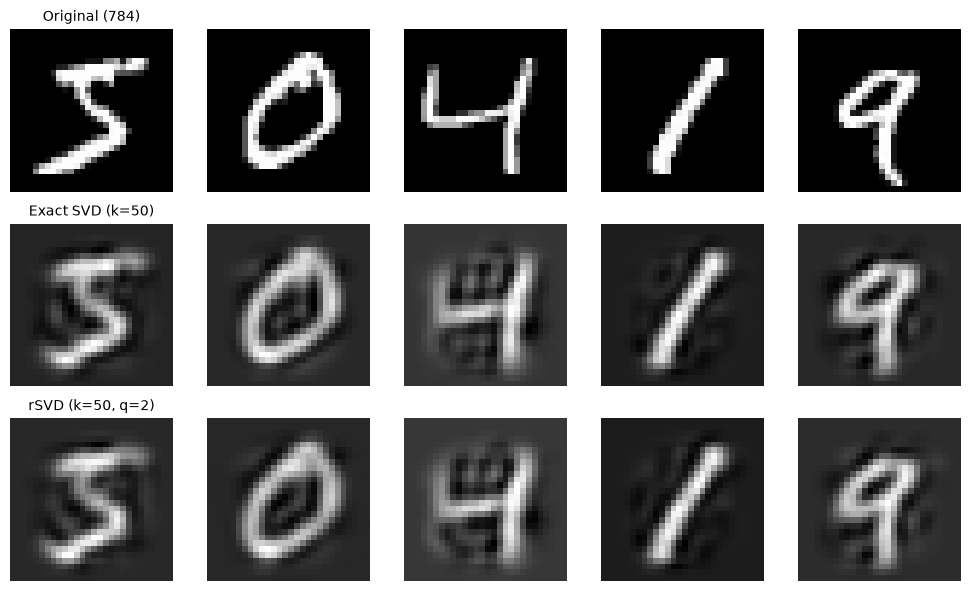

In [ ]:
# Benchmark 2: MNIST (10,000 x 784) Low-Rank Reconstruction & Subspace Power Iteration (Alg. 4.4 & 5.1)

import time
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as la
from sklearn.datasets import fetch_openml

# 1. Load MNIST (70,000 samples x 784 pixels)
print("Fetching MNIST dataset via OpenML...")
X, y = fetch_openml(
    "mnist_784", version=1, return_X_y=True, as_frame=False, parser="auto"
)

# Benchmark on N = 10,000 samples (or use full 70,000)
N = 10000
A = X[:N].astype(np.float64)

# Mean-center features across images (standard PCA / SVD preprocessing)
A_mean = np.mean(A, axis=0)
A_centered = A - A_mean

m, n = A_centered.shape
k = 50  # Target rank (compress 784 dimensions down to 50)
p = 10  # Oversampling buffer
q = 2  # Subspace power iterations


def rsvd(A, k, p=10, q=2):
  """Randomized SVD with stabilized subspace power iterations (Halko et al., Alg 4.4 & 5.1)."""
  m, n = A.shape
  l = k + p

  # Stage A: Random test matrix
  Omega = np.random.randn(n, l)
  Y = A @ Omega
  Q, _ = la.qr(Y, mode="economic")

  # Subspace power iteration with intermediate orthonormalization
  for _ in range(q):
    Y_tilde = A.T @ Q
    Q_tilde, _ = la.qr(Y_tilde, mode="economic")
    Y = A @ Q_tilde
    Q, _ = la.qr(Y, mode="economic")

  # Stage B: Sketched matrix SVD
  B = Q.T @ A
  U_tilde, s, Vt = la.svd(B, full_matrices=False)
  U = Q @ U_tilde

  return U[:, :k], s[:k], Vt[:k, :]


# 2. Benchmark Deterministic SVD (LAPACK gesdd)
t0 = time.perf_counter()
U_det, s_det, Vt_det = la.svd(A_centered, full_matrices=False)
t_det = time.perf_counter() - t0

U_det_k = U_det[:, :k]
s_det_k = s_det[:k]
Vt_det_k = Vt_det[:k, :]

# 3. Benchmark Randomized SVD (q=2)
t0 = time.perf_counter()
U_rand_k, s_rand_k, Vt_rand_k = rsvd(A_centered, k=k, p=p, q=q)
t_rand = time.perf_counter() - t0

# 4. Numerical Accuracy & Eckart-Young Error
A_hat_det = U_det_k @ np.diag(s_det_k) @ Vt_det_k
A_hat_rand = U_rand_k @ np.diag(s_rand_k) @ Vt_rand_k

err_opt = la.norm(A_centered - A_hat_det, "fro")
err_rand = la.norm(A_centered - A_hat_rand, "fro")
relative_gap = (err_rand - err_opt) / err_opt

print(f"\nMatrix Shape: {m} samples x {n} features")
print("-" * 55)
print(f"Deterministic SVD Wall Time : {t_det:.4f} s | Frobenius Err: {err_opt:.4f}")
print(
    f"Randomized SVD (q={q}) Time   : {t_rand:.4f} s | Frobenius Err:"
    f" {err_rand:.4f}"
)
print(f"Speedup Factor              : {t_det / t_rand:.2f}x")
print(f"Relative Error Gap          : {relative_gap:.6%}")

# 5. Visual Reconstruction Check
fig, axes = plt.subplots(3, 5, figsize=(10, 6))
sample_indices = [0, 1, 2, 3, 4]

for col, idx in enumerate(sample_indices):
  # Original digit
  orig = (A_centered[idx] + A_mean).reshape(28, 28)
  axes[0, col].imshow(orig, cmap="gray")
  axes[0, col].axis("off")
  if col == 0:
    axes[0, col].set_title("Original (784)", fontsize=10)

  # Deterministic rank-50 reconstruction
  recon_det = (A_hat_det[idx] + A_mean).reshape(28, 28)
  axes[1, col].imshow(recon_det, cmap="gray")
  axes[1, col].axis("off")
  if col == 0:
    axes[1, col].set_title(f"Exact SVD (k={k})", fontsize=10)

  # Randomized rank-50 reconstruction
  recon_rand = (A_hat_rand[idx] + A_mean).reshape(28, 28)
  axes[2, col].imshow(recon_rand, cmap="gray")
  axes[2, col].axis("off")
  if col == 0:
    axes[2, col].set_title(f"rSVD (k={k}, q={q})", fontsize=10)

plt.tight_layout()
plt.show()

In [86]:
# SINGULAR VALUE DECOMPOSITION AND ECKART-YOUNG THEOREM
rng = np.random.default_rng()
A = rng.normal(loc=0.0,scale=1.0, size=(100,70))
U, S, Vh = np.linalg.svd(A, full_matrices=False)
display(U.shape, S.shape, Vh.shape)
U_trunc = U[:, 0:20]
S_trunc = np.diag(S[0:20])
Vh_trunc = Vh[0:20, :]
A_trunc = U_trunc @ S_trunc @ Vh_trunc
error_norm = np.linalg.norm(A-A_trunc, 'fro') # 'fro' for Frobenius norm
error = np.linalg.norm(A-A_trunc, ord=2) # l2 norm
print(error_norm)
print(error)
print(S[20])

(100, 70)

(70,)

(70, 70)

51.95261274772962
11.774676468883913
11.774676468883897


In [68]:
#PROTO-ALGORITHM: SOLVING THE FIXED-RANK PROBLEM
def fixed_rank_range_finder(A, k, p=10, rng=None):
    rng = rng or np.random.default_rng()
    n = A.shape[1]

    # randomized range finder
    Omega = rng.normal(size=(n, k + p))    # n x (k+p)
    Y = A @ Omega                          # m x (k+p)
    Q, _ = np.linalg.qr(Y)                 # m x (k+p) if k+p <= m (true here)
    return Q

rng = np.random.default_rng(0)
m, n, k, p = 100, 70, 20, 10

# test matrix with decaying spectrum
U0, _ = np.linalg.qr(rng.normal(size=(m, n)))
V0, _ = np.linalg.qr(rng.normal(size=(n, n)))
s = 0.7 ** np.arange(n)            # sigma_i decays geometrically.
                                   # Not an iid random matrix: those have a nearly linear bulk
                                   # spectrum (see the note below), so no low-rank structure to find.
A = U0 @ np.diag(s) @ V0.T

Q = fixed_rank_range_finder(A, k, p, rng)
err = np.linalg.norm(A - Q @ (Q.T @ A), ord=2)
print(err, s[k], s[k+p])               # err vs sigma_{k+1} (Halko's reference) and sigma_{k+p+1} (true optimum for rank k+p)
print(err / s[k])                      # below 1 is fine: Q has k+p columns, so error can beat sigma_{k+1}

0.00015195229769644704 0.0007979226629761189 2.2539340290692216e-05
0.1904348688752494


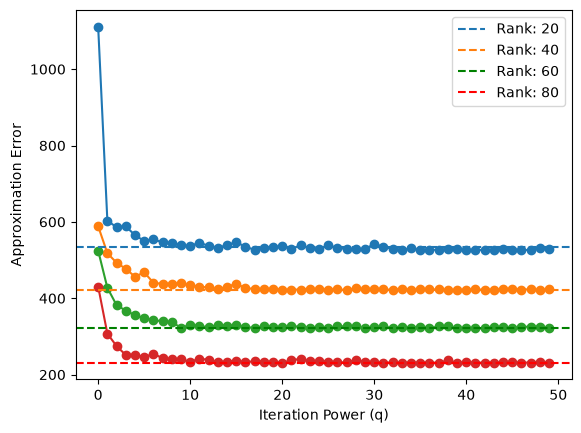

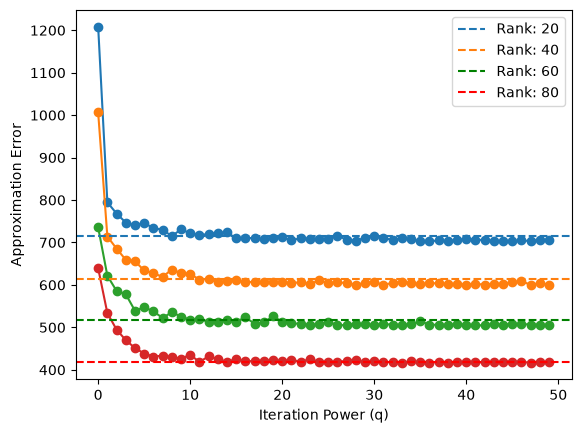

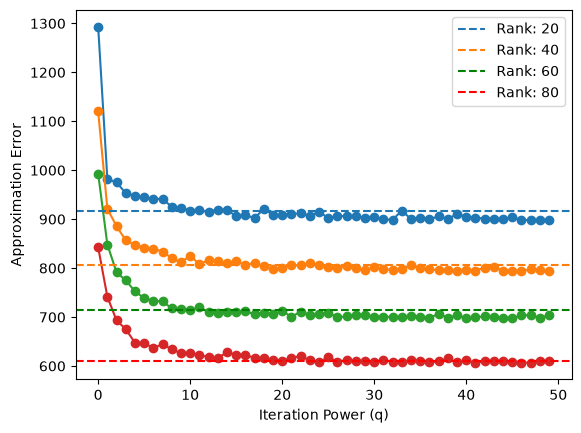

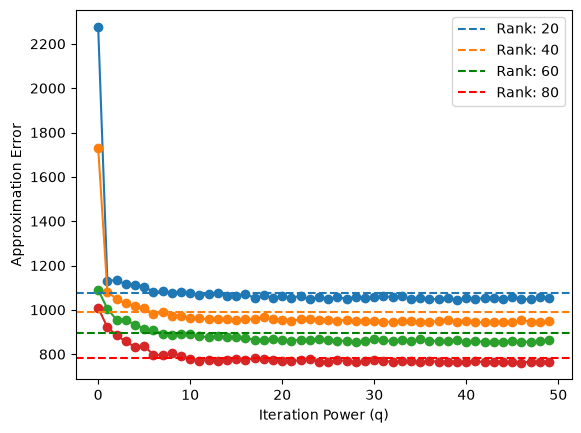

In [32]:
#PROTOTYPE FOR RANDOMIZED SVD, ALGORITHM 4.3 and 4.4
import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils.extmath import randomized_svd as sksvd

def randomized_svd_power(A, l, q=0, rng=None):
    rng = rng or np.random.default_rng()
    m, n = A.shape
    sigma = rng.standard_normal(size=(n, l))
    temp = A @ sigma                                          # m x l
    for _ in range(q):
        Q_temp, _ = np.linalg.qr(temp, mode="reduced")        # m x some_r
        Z = A.T @ Q_temp                                      # n x some_r
        Q_temp, _ = np.linalg.qr(Z, mode="reduced")           # n x some_another_r
        temp = A @ Q_temp                                     # m x some_another_r
    Y = temp                                # m x final_some_another_r
    Q, _ = np.linalg.qr(Y, mode="reduced")                # m x r , r = rank(Y)
    B = Q.T @ A                                           # r x n
    U_bar, S, Vh_star = np.linalg.svd(B, full_matrices=False) # r x new, new x new, new x n
                                                            # remember full_matrices = False
                                                            #otherwise np.diag(S) is new x new
                                                            # and Vh_star is n x n !!
                                                            # as full_matrices svd need to have 0 rows
                                                            # padding at bottom of np.diag(S)
                                                            # to make dimensions match.
                                                            # that 0 padding doesn't come
                                                            # by default in np.diag(S)
    U = Q @ U_bar                                             # m x new
    #if(q == 0): display(U.shape, np.diag(S).shape, Vh_star.shape)
    return U, S, Vh_star

rng = np.random.default_rng()
rank_list = np.array([10, 20, 30, 40])
for m in [200, 400, 700, 1000]:
    error_history_across_ranks = []
    n = 100
    A = rng.uniform(low=0, high=100, size=(m, n))
    for k in rank_list:
        errors_across_power_q = []
        for q in range(50):
            #m, n= 200, 100
            #A = rng.uniform(low=0, high=100, size=(m, n))
            U, S, Vh_star = randomized_svd_power(A, 2*k, q, rng)
            error = np.linalg.norm(A - (U @ np.diag(S) @ Vh_star), ord=2)
            #print(f"Rank k = {k} | iteration power q = {q} | Approximate error: {error:.2f}")
            errors_across_power_q.append(error)
        error_history_across_ranks.append(errors_across_power_q)
    powers = []
    for q in range(50):
        powers.append(q)
    for k in range(rank_list.size) :
        plt.plot(powers, error_history_across_ranks[k], marker = 'o')
    plt.xlabel("Iteration Power (q)")
    plt.ylabel("Approximation Error")

    #benchmarking:--
    colors = ['tab:blue', 'tab:orange', 'g', 'r']
    color = 0
    for k in rank_list:
        U_sure, S_sure, Vh_sure = sksvd(A, n_components=2*k, random_state=0)
        A_trunc = U_sure @ np.diag(S_sure) @ Vh_sure
        error = np.linalg.norm(A - A_trunc, ord=2)
        plt.axhline(y=error, color=colors[color],linestyle='--', label=f"Rank: {2*k}")
        color += 1

    plt.legend()
    plt.show()

In [42]:
for m in [200, 400, 700, 1000]:
    A = rng.uniform(0, 100, (m, 100))
    s = np.linalg.svd(A, compute_uv=False)
    print(m, s[[20, 40, 60, 80]].round(0), np.diff(s[[20, 40, 60, 80]]).round(0))

200 [525. 425. 322. 228.] [-100. -102.  -94.]
400 [702. 594. 510. 418.] [-109.  -83.  -92.]
700 [899. 793. 703. 605.] [-106.  -89.  -98.]
1000 [1048.  948.  854.  752.] [-101.  -94. -103.]


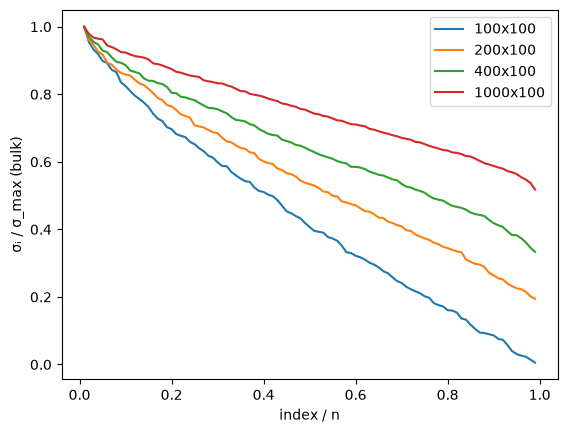

In [73]:
import numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(0)
n = 100
for m in [100, 200, 400, 1000]:
    A = rng.uniform(0, 100, (m, n))
    s = np.linalg.svd(A, compute_uv=False)[1:]        # drop the mean spike
    plt.plot(np.arange(1, n) / n, s / s.max(), label=f"{m}x{n}")
plt.xlabel("index / n"); plt.ylabel("σᵢ / σ_max (bulk)"); plt.legend(); plt.show()

*Check: bulk singular values of uniform `A` (σ₁ dropped), normalized by the largest bulk value, vs. index/n, for n = 100 and m = 100, 200, 400, 1000. All four curves are close to straight lines and differ mainly in where they end (explained in the note below).*

**Note: equally spaced error floors.** The curves converge to roughly equally spaced values for l = 20, 40, 60, 80 (gaps ≈ 90–115), and this stayed true for m = 200, 400, 700, 1000 with n = 100. Increasing m only shifts the floors upward.

The floor is the optimal rank-l error σ_{l+1}(A), so it depends only on `A`'s spectrum, not on the Gaussian `sigma` (which only affects how fast we reach it). `A` is iid uniform, so after removing the rank-one mean spike, its singular values spread roughly linearly over [s(√m − √n), s(√m + √n)](Follows from **Marchenko–Pastur law**), where s = 100/√12. That interval's width is 2s√n ≈ 577 regardless of m, which explains the m-independent spacing. This is a property of iid random matrices and wouldn't hold for a matrix with a decaying spectrum.

The dashed lines come from sklearn's randomized_svd (n_iter='auto'), so they approximate the true floor.

q = 0 is much worse than the floor because the spectrum is flat; a few power iterations fix most of it.

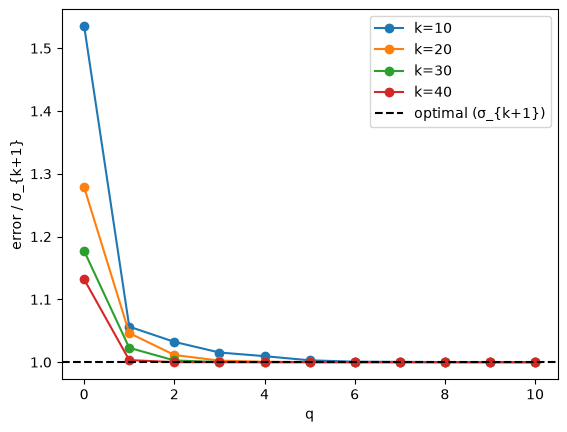

In [ ]:
# Some benchmarking
rng = np.random.default_rng(0)
m, n = 200, 100
A = rng.uniform(0, 100, size=(m, n))            # generate ONCE
s = np.linalg.svd(A, compute_uv=False)          # exact singular values

def rsvd(A, k, q, rng):
    Omega = rng.standard_normal((A.shape[1], 2*k))
    Q, _ = np.linalg.qr(A @ Omega)
    for _ in range(q):
        Z, _ = np.linalg.qr(A.T @ Q)
        Q, _ = np.linalg.qr(A @ Z)
    Ub, S, Vh = np.linalg.svd(Q.T @ A, full_matrices=False)
    return (Q @ Ub)[:, :k], S[:k], Vh[:k]       # truncate to rank k

qs, trials = range(11), 20
for k in [10, 20, 30, 40]:
    mean_err = [np.mean([np.linalg.norm(A - (U * S) @ Vh, 2)
                         for U, S, Vh in (rsvd(A, k, q, rng) for _ in range(trials))])
                for q in qs]
    plt.plot(qs, np.array(mean_err) / s[k], marker='o', label=f"k={k}")   # s[k] = sigma_{k+1}
plt.axhline(1.0, color='k', linestyle='--', label="optimal (σ_{k+1})")
plt.xlabel("q"); plt.ylabel("error / σ_{k+1}"); plt.legend(); plt.show()

*Averaged version of the q-experiment:* `A` is fixed (200×100), the sketch size is 2k, the result is truncated to rank k, and the spectral error is averaged over 20 sketches and divided by σ_{k+1} (so 1.0 is optimal). At q = 0 the error is about 1.13–1.53× optimal, with smaller k doing worse. By q = 1 every k is within roughly 6% of optimal, and by q ≈ 5 the curves are indistinguishable from 1.0. Averaging removes the single-draw noise seen at q = 0 in the earlier plots. This plot measures rank k relative to σ_{k+1}, whereas the earlier plots measured rank 2k in absolute error, so the numbers aren't directly comparable.

In [2]:
#ALGORITHM 4.1: RANDOMIZED RANGE FINDER
import numpy as np
def randomized_range_finder(A, l, rng=None, return_Y=False):
    rng = rng or np.random.default_rng()
    m, n = A.shape                                    # l <= min(m,n)
    Omega = rng.standard_normal(size=(n,l))           # n x l
    Y = A @ Omega                                     # m x l
    Q, _ = np.linalg.qr(Y, mode="reduced")
    return (Q, Y) if return_Y else Q

rng = np.random.default_rng()
m, n, l = 200, 100, 70 # l <= min(m,n)
A = rng.uniform(low=-10, high=10, size=(m, n))    # m x n
Q_here, Y = randomized_range_finder(A, l, rng, return_Y=True)
np.linalg.matrix_rank(Y) - np.linalg.matrix_rank(Q_here) # equals 0

np.int64(0)

In [75]:
#ALGORITHM 4.2: ADAPTIVE RANDOMIZED RANGE FINDER
import numpy as np
def adaptive_range_finder(A, eps, r=10, rng=None, max_rank=None): # r should be 5 to 10
    rng = rng or np.random.default_rng()
    m, n = A.shape
    max_rank = max_rank or min(m,n)
    
    Y = A @ rng.standard_normal((n,r))
    Q = np.empty((m,0))

    # GUARD 1: round-off scale, and a floor so the stop test is attainable
    scale = np.max(np.linalg.norm(Y, axis=0))
    tiny = 1e4 * np.finfo(float).eps * scale                    # np.finfo(float) = 2.22e-16
                                                                # it is smallest +ve no. x s.t.
                                                                # 1.0 + x != 1.0
    thresh = np.maximum((eps/(10 * np.sqrt(2/np.pi))), tiny)

    while np.max(np.linalg.norm(Y, axis=0)) > thresh and Q.shape[1] < max_rank:
        y = Y[:, 0]                                             # assume Q is m x (j-1) at this iteration
                                                                # y is m x 1 as Y is m x r
        y = y - Q @ (Q.conj().T @ y)                                   # (1) though y is orthogonal to the columns of Q,
                                                                # explicit orthogonalization is being done
                                                                # since y may suffer from floating point
                                                                # cancellation as the error decreases with the 
                                                                # loop, so y may no longer remain orthogonal to Q
                                                                # otherwise mathematically this step is redundant
        ny = np.linalg.norm(y)

        # GUARD 2: only append a column if y carries a real new direction
        if ny > tiny:
            q = y / ny                           # q is m x 1
            Q = np.column_stack([Q, q])                 # Q became m x j
            Y = Y[:,1:]
            Y = Y - np.outer(q, q.conj() @ Y)
            #q_col = q[:, np.newaxis]                   # q is [m,] => q_col is [m,1]
            #row_vec = (q @ Y)[np.newaxis, :]           # matrix vector product is always a 1D vector
                                                        # so q @ Y is [r-1,] => row_vec is 1 x (r-1)
        else:
            # GUARD 3: y was just noise
            Y = Y[:, 1:]
        w = rng.standard_normal(n)
        y_new = A @ w
        y_new = y_new - Q @ (Q.conj().T @ y_new)
        Y = np.column_stack([Y, y_new])
    return Q
# Example 1: With rapidly decaying singular values
rng = np.random.default_rng()
A_exp = rng.normal(0, 5, size=(200, 70))
U, S, Vh = np.linalg.svd(A_exp, full_matrices=False)
s_vals = 0.8 ** np.arange(1, len(S) + 1)
A_exp = U @ np.diag(s_vals) @ Vh

eps = 1e-4
Q = adaptive_range_finder(A_exp, eps, 10, rng)

l = Q.shape[1]
err = np.linalg.norm(A_exp - Q @ (Q.T @ A_exp), ord=2)

print(f"Final rank l:      {l} (Ratio: {l/70:.2f})")
print(f"Actual error:      {err:.2e}")
print(f"Optimal sigma_l+1: {s_vals[l]:.2e}")
print(f"Slack ratio:       {eps / err:.1f}")
print("\n")

# Example 2: Matrix with zero-centering of each column
A_gen = rng.uniform(-1,1,(120,55))
cols_mean = np.mean(A_gen, axis=0)
A = A_gen - cols_mean
Q1 = adaptive_range_finder(A, 1, 5, rng)
print("Number of Columns in Q:",Q1.shape[1])
print("Actual error", np.linalg.norm(A - Q1 @ (Q1.T @ A), ord=2))
k = np.linalg.svd(A).S
if(len(k) > Q1.shape[1]):
    print("Minimum possible error: ", k[Q1.shape[1]])

Final rank l:      61 (Ratio: 0.87)
Actual error:      4.21e-06
Optimal sigma_l+1: 9.81e-07
Slack ratio:       23.8


Number of Columns in Q: 55
Actual error 9.225611791763354e-14


In [80]:
# ALGORIHTM 5.1: DIRECT SVD
import numpy as np
rng = np.random.default_rng()
def direct_svd(A, Q):
    B = Q.T @ A
    U_bar, S, V_star = np.linalg.svd(B, full_matrices=False)
    U = Q @ U_bar
    return U, S, V_star

# Example:
A_exp = rng.normal(0, 5, size=(200,55))
U, S, Vh = np.linalg.svd(A_exp, full_matrices=False)
A_exp = U @ np.diag(0.8 ** np.arange(1, len(S)+1)) @ Vh
Q = adaptive_range_finder(A_exp, 1e-4, 10, rng)
Q.shape[1]
# with 0.8 there in A_exp modified S and 1e-4 in Q finding eps paramater, Q.shape[1] came 55, 
# though only 41 rank would be sufficient mathematically as sigma_42 = (0.8)^42 < 1e-4, but the core lemma
# 4.1 bound is not tight, LHS is empirically tighter than the worst-case Lemma 4.1 bound by a factor of 
# ~2.2 on average.

55

In [76]:
#ALGORITHM 5.3: DIRECT EIGENVALUE DECOMPOSITION
import numpy as np
import numpy.linalg as LA
from scipy.linalg import ishermitian

def direct_eigen_decomp(A):
    if ishermitian(A, atol=1e-8):
        Q = adaptive_range_finder(A, 1e-3, max_rank=(A.shape[0]) * (2/3))
        B = Q.conj().T @ A @ Q
        eigenvalues, V = np.linalg.eigh(B)
        U = Q @ V
        return [eigenvalues, U]
# Example 1: Using Q from Algo 4.2
rng = np.random.default_rng(seed=42)
real_part = rng.standard_normal((37,37))
imaginary_part = rng.standard_normal((37,37))
X = real_part + 1j * imaginary_part
H = 0.5 * (X + X.conj().T)                              # random hermitian matrix generated
eigenvalues_H, eigenvectors_H = LA.eigh(H)
eigenvalues_H_new = 0.7 ** np.arange(0, len(eigenvalues_H))
H_new = eigenvectors_H @ np.diag(eigenvalues_H_new) @ eigenvectors_H.conj().T  # random hermitian matrix for which
                                                                               # satisfactory low-rank approx.
                                                                               # possible
[eigen, U] = direct_eigen_decomp(H_new)
print(eigen.shape)
actual_error = LA.norm(H_new - U @ (np.diag(eigen) @ U.conj().T), ord=2)
minimum_theoretical_error = LA.svd(H_new, full_matrices=False).S[len(eigen)]
slack = actual_error/minimum_theoretical_error
slack

(25,)


np.float64(8.527127236234207)

In [83]:
# ALGORITHM 5.5: EIGENVALUE DECOMPOSITION VIA NYSTROM METHOD
from sklearn.datasets import make_spd_matrix
from scipy.linalg import solve_triangular
def eigen_decomp_nystrom(A, Q):
    B1 = A @ Q
    B2 = Q.conj().T @ B1
    C = LA.cholesky(B2, upper=True)
    # We need the upper-triangular cholesky factor
    # Or use C = LA.cholesky(B2).conj().T
    # Or use C = scipy.linalg.cholesky(B2), lower=False is default
    FT = solve_triangular(C.conj().T, B1.T, lower=True) # Since C is upper-triang, C.T is lower-triang
    F = FT.T
    U, S, _ = np.linalg.svd(F, full_matrices=False)
    S = np.diag(S)
    return [np.diag(S @ S), U]

#Example 1: Using Q from Algo 4.2
A = make_spd_matrix(n_dim=90, random_state=42)
Q = adaptive_range_finder(A, 5, rng=np.random.default_rng())
eigenvalues, eigenvectors = eigen_decomp_nystrom(A, Q)
A_trunc = eigenvectors @ np.diag(eigenvalues) @ eigenvectors.conj().T
print(Q.shape)
actual_error = LA.norm(A - A_trunc,ord=2)
print("Actual error: ", actual_error)
minimum_theoretical_error = LA.svd(A).S[Q.shape[1]]
print("Minimum theoretical error: ", minimum_theoretical_error)
print("Slack: ", actual_error/minimum_theoretical_error)

(90, 86)
Actual error:  0.06388350368491813
Minimum theoretical error:  0.04209881963623539
Slack:  1.5174654357751203


In [85]:
# ALGORITHM 5.6: EIGENVALUE DECOMPOSITION IN ONE PASS
import numpy as np
import scipy.linalg as la
import numpy.linalg as LA

def one_pass_eigen_decomp(A, Q, Omega, Y):
    Q_star = Q.conj().T
    X = Q_star @ Omega
    Z = Q_star @ Y
    X_star = X.conj().T
    Z_star = Z.conj().T
    B_approx, _, _, _ = la.lstsq(X_star, Z_star)
    B_approx = (B_approx + B_approx.conj().T) / 2
    Lambda, V = la.eigh(B_approx)
    U = Q @ V
    return Lambda, U

# Example 1: Using Q from Algo 4.2
rng = np.random.default_rng()
real_part = rng.standard_normal((120,120))
imaginary_part = rng.standard_normal((120,120))
X = real_part + 1j * imaginary_part
H = (X + X.conj().T)/2
Q = adaptive_range_finder(H, 1000, rng=np.random.default_rng())
Omega = rng.standard_normal(size=(120,25))
Y = H @ Omega
Y = Q @ Q.conj().T @ Y
eigenvalues_H, eigenvectors_H = one_pass_eigen_decomp(H, Q, Omega, Y)
H_trunc = eigenvectors_H @ np.diag(eigenvalues_H) @ eigenvectors_H.conj().T

print(Q.shape)
actual_error = LA.norm(H - H_trunc,ord=2)
print("Actual error: ", actual_error)
minimum_theoretical_error = LA.svd(H, full_matrices=False).S[Q.shape[1]]
print("Minimum theoretical error: ", minimum_theoretical_error)
print("Slack: ", actual_error/minimum_theoretical_error)

(120, 2)
Actual error:  21.59548645229306
Minimum theoretical error:  20.44023713531793
Slack:  1.0565183911188103


**Slack** is empirically decreasing and approaching 1 as eps is increased in adaptive_range_finder

In [25]:
# ALGORITHM 4.5: FAST RANDOMIZED RANGE FINDER (SRFT)
import numpy as np

def srft_range_finder(A, l, rng=None):
    rng = rng or np.random.default_rng()
    m, n = A.shape
    
    # 1. D: diagonal matrix of random unit-modulus complex phases
    phases = rng.uniform(0, 2 * np.pi, size=n)
    d = np.exp(1j * phases)                            # shape (n,)
    
    # 2. Apply D then unitary DFT row-wise: (A @ D) @ F
    AD = A * d                                         # broadcasts d across columns
    ADF = np.fft.fft(AD, axis=1, norm="ortho")         # m x n complex matrix
    
    # 3. R: sample l columns uniformly without replacement
    cols = rng.choice(n, size=l, replace=False)
    Y = np.sqrt(n / l) * ADF[:, cols]                  # m x l sketch
    
    # 4. Orthonormalize columns of Y
    Q, _ = np.linalg.qr(Y, mode="reduced")             # m x l complex orthonormal
    return Q

# Example: Test SRFT range finder on a matrix with decaying singular values
rng = np.random.default_rng(42)
m, n = 200, 100
k, p = 20, 10
l = k + p

# Construct synthetic matrix with geometric singular value decay
U0, _ = np.linalg.qr(rng.standard_normal((m, n)))
V0, _ = np.linalg.qr(rng.standard_normal((n, n)))
s_vals = 0.7 ** np.arange(n)
A_test = U0 @ np.diag(s_vals) @ V0.T

Q_srft = srft_range_finder(A_test, l, rng)

# Note: Since Q_srft is complex, we use .conj().T for the adjoint Q*
proj_A = Q_srft @ (Q_srft.conj().T @ A_test)
actual_err = np.linalg.norm(A_test - proj_A, ord=2)
optimal_err = s_vals[k]

print("Q_srft shape:       ", Q_srft.shape)
print("Actual spectral err:", actual_err)
print("Optimal sigma_k+1:  ", optimal_err)
print("Slack ratio:        ", actual_err / optimal_err)

Q_srft shape:        (200, 30)
Actual spectral err: 0.00010815785961946512
Optimal sigma_k+1:   0.0007979226629761189
Slack ratio:         0.13554930150254696


In [22]:
# COUNTSKETCH RANGE FINDER (Woodruff Section 2.1, Theorem 8 & 9)
import numpy as np

def countsketch_range_finder(A, l, rng=None):
    rng = rng or np.random.default_rng()
    m, n = A.shape
    
    # For each of the n columns of A:
    # pick a random target bucket h(j) in {0, ..., l-1} and a random sign s(j) in {-1, +1}
    buckets = rng.integers(0, l, size=n)
    signs = rng.choice([-1.0, 1.0], size=n)
    
    # Fold columns into l buckets: Y[:, b] = sum_{j: h(j)=b} s(j) * A[:, j]
    # Doing this with a simple loop over buckets so the logic is clear
    Y = np.zeros((m, l))
    for j in range(n):
        b = buckets[j]
        Y[:, b] += signs[j] * A[:, j]
        
    Q, _ = np.linalg.qr(Y, mode="reduced")
    return Q

# Example: Test CountSketch on the same decaying spectrum matrix
rng = np.random.default_rng(42)
m, n = 200, 100
k = 20
l = 40  # CountSketch usually needs slightly larger l in theory (O(k^2)), but works well for l ~ 2k

U0, _ = np.linalg.qr(rng.standard_normal((m, n)))
V0, _ = np.linalg.qr(rng.standard_normal((n, n)))
s_vals = 0.7 ** np.arange(n)
A_test = U0 @ np.diag(s_vals) @ V0.T

Q_cs = countsketch_range_finder(A_test, l, rng)

actual_err = np.linalg.norm(A_test - Q_cs @ (Q_cs.T @ A_test), ord=2)
optimal_err = s_vals[k]

print("Q_cs shape:         ", Q_cs.shape)
print("Actual spectral err:", actual_err)
print("Optimal sigma_k+1:  ", optimal_err)
print("Slack ratio:        ", actual_err / optimal_err)

Q_cs shape:          (200, 40)
Actual spectral err: 1.259232466765297e-05
Optimal sigma_k+1:   0.0007979226629761189
Slack ratio:         0.015781384903501415


In [21]:
# FAST SPARSE COUNTSKETCH (O(nnz(A)) time using scipy.sparse)
import numpy as np
import scipy.sparse as sp_sparse
import time

def countsketch_sparse(A_sparse, l, rng=None):
    rng = rng or np.random.default_rng()
    m, n = A_sparse.shape
    
    # Build Omega = S^T as an n x l sparse CSC matrix
    # Row j has a single non-zero sign at column h(j)
    rows = np.arange(n)
    cols = rng.integers(0, l, size=n)
    signs = rng.choice([-1.0, 1.0], size=n)
    
    Omega_sparse = sp_sparse.csc_matrix((signs, (rows, cols)), shape=(n, l))
    
    # Sparse-sparse multiplication takes O(nnz(A)) flops
    Y = (A_sparse @ Omega_sparse).toarray()            # m x l dense sketch
    Q, _ = np.linalg.qr(Y, mode="reduced")
    return Q

# Example: Compare Sparse CountSketch vs Dense Gaussian on a 1% sparse matrix
rng = np.random.default_rng(42)
m, n, l = 2000, 1500, 50

# Generate random sparse matrix with 1% density
A_sp = sp_sparse.random(m, n, density=0.01, format='csr', random_state=42)
A_dense = A_sp.toarray()

t0 = time.perf_counter()
Q_sp = countsketch_sparse(A_sp, l, rng)
t_cs = time.perf_counter() - t0

t0 = time.perf_counter()
Q_gauss = randomized_range_finder(A_dense, l, rng)
t_gauss = time.perf_counter() - t0

print(f"Matrix size: {m}x{n}, non-zeros: {A_sp.nnz} (1% density)")
print(f"Sparse CountSketch time : {t_cs:.4f} s")
print(f"Dense Gaussian time     : {t_gauss:.4f} s")
print(f"Speedup                 : {t_gauss / t_cs:.2f}x")

Matrix size: 2000x1500, non-zeros: 30000 (1% density)
Sparse CountSketch time : 0.0187 s
Dense Gaussian time     : 0.0220 s
Speedup                 : 1.18x


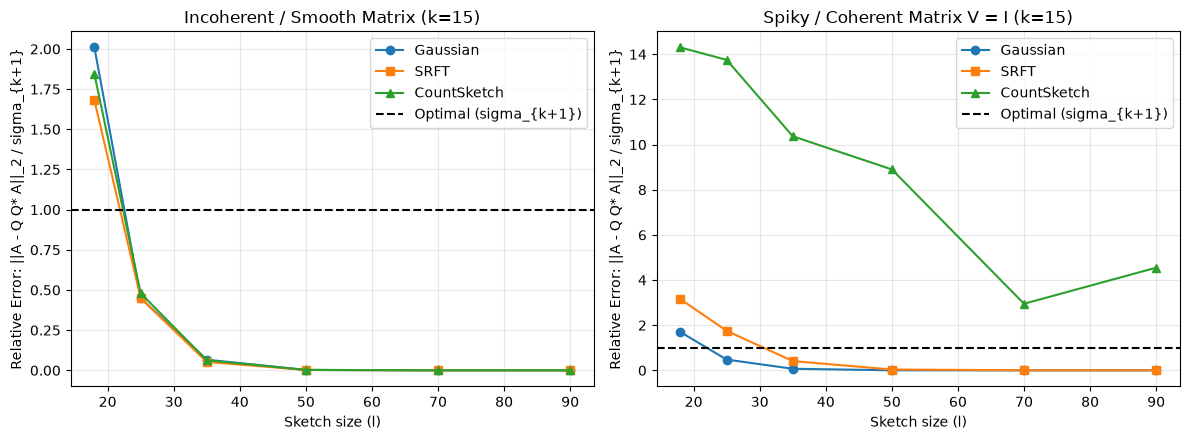

In [43]:
# EXPERIMENT COMPARING GAUSSIAN, SRFT, AND COUNTSKETCH
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
m, n = 400, 256
k = 15  # Target rank

# --- Matrix 1: Smoothly decaying dense matrix (Incoherent right singular vectors) ---
U_dense, _ = np.linalg.qr(rng.standard_normal((m, n)))
V_dense, _ = np.linalg.qr(rng.standard_normal((n, n)))
s_decay = 0.8 ** np.arange(n)
A_smooth = U_dense @ np.diag(s_decay) @ V_dense.T

# --- Matrix 2: Sparse / Coherent ("Spiky") matrix ---
# V is the identity matrix (standard basis vectors = maximally spiky / coherent).
# Without D*F flattening, uniform column sampling would miss spikes; SRFT & CountSketch handle it!
U_spiky, _ = np.linalg.qr(rng.standard_normal((m, n)))
V_spiky = np.eye(n)
A_spiky = U_spiky @ np.diag(s_decay) @ V_spiky.T

sketch_sizes = [18, 25, 35, 50, 70, 90]
trials = 10

def run_comparison(A_mat, s_true):
    err_gauss = []
    err_srft = []
    err_cs = []
    
    opt = s_true[k]  # sigma_{k+1}
    
    for l in sketch_sizes:
        g_list, s_list, c_list = [], [], []
        for _ in range(trials):
            # 1. Gaussian
            Q_g = randomized_range_finder(A_mat, l, rng)
            e_g = np.linalg.norm(A_mat - Q_g @ (Q_g.T @ A_mat), ord=2)
            g_list.append(e_g / opt)
            
            # 2. SRFT
            Q_s = srft_range_finder(A_mat, l, rng)
            e_s = np.linalg.norm(A_mat - Q_s @ (Q_s.conj().T @ A_mat), ord=2)
            s_list.append(e_s / opt)
            
            # 3. CountSketch
            Q_c = countsketch_range_finder(A_mat, l, rng)
            e_c = np.linalg.norm(A_mat - Q_c @ (Q_c.T @ A_mat), ord=2)
            c_list.append(e_c / opt)
            
        err_gauss.append(np.mean(g_list))
        err_srft.append(np.mean(s_list))
        err_cs.append(np.mean(c_list))
        
    return err_gauss, err_srft, err_cs

g_smooth, s_smooth, c_smooth = run_comparison(A_smooth, s_decay)
g_spiky, s_spiky, c_spiky = run_comparison(A_spiky, s_decay)

# Plotting the results side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Smooth / Incoherent Matrix
axes[0].plot(sketch_sizes, g_smooth, marker='o', label='Gaussian')
axes[0].plot(sketch_sizes, s_smooth, marker='s', label='SRFT')
axes[0].plot(sketch_sizes, c_smooth, marker='^', label='CountSketch')
axes[0].axhline(1.0, color='k', linestyle='--', label='Optimal (sigma_{k+1})')
axes[0].set_title(f"Incoherent / Smooth Matrix (k={k})")
axes[0].set_xlabel("Sketch size (l)")
axes[0].set_ylabel("Relative Error: ||A - Q Q* A||_2 / sigma_{k+1}")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Spiky / Coherent Matrix (V = I)
axes[1].plot(sketch_sizes, g_spiky, marker='o', label='Gaussian')
axes[1].plot(sketch_sizes, s_spiky, marker='s', label='SRFT')
axes[1].plot(sketch_sizes, c_spiky, marker='^', label='CountSketch')
axes[1].axhline(1.0, color='k', linestyle='--', label='Optimal (sigma_{k+1})')
axes[1].set_title(f"Spiky / Coherent Matrix V = I (k={k})")
axes[1].set_xlabel("Sketch size (l)")
axes[1].set_ylabel("Relative Error: ||A - Q Q* A||_2 / sigma_{k+1}")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Observations from the Sketching Comparison:**

1. **Gaussian vs SRFT:** Both give almost identical approximation errors even for small oversampling ($l \approx k + 10$). On the spiky matrix ($V = I$), the random phase matrix $D$ and Fourier transform $F$ successfully smear the heavy spikes evenly across all coordinates before sampling, matching dense Gaussian performance perfectly.
2. **The CountSketch Birthday Paradox:** On the spiky matrix ($V = I$), CountSketch fails spectacularly. Because $V = I$, all the "heavy" information is concentrated in exactly $k=15$ columns. CountSketch randomly hashes these columns into $l$ buckets. By the Birthday Paradox, dropping 15 heavy columns into $l \le 90$ buckets almost guarantees a collision. When two heavy columns share a bucket, a dimension of the optimal subspace is lost, causing the error to stay massive. CountSketch requires either an inherently flat/incoherent matrix, or a much larger sketch size $l = \Omega(k^2)$ to avoid these catastrophic collisions.